<a href="https://colab.research.google.com/github/nandamanohar/ICT-intermediate-assessment-and-case-study/blob/main/Unsupervised_Learning_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
export=pd.read_csv('/content/export_orders.csv')
export.head()

,order_id,order_date,customer_id,country,product_category,quantity,unit_price,discount_pct,total_amount,shipping_mode,shipping_days,payment_terms,customer_rating,delayed,returned
0,EXP1001,2025-01-01,C160,UAE,Spices,301,17.97,5,5138.52,Sea,12.0,LC,5.0,0,0
1,EXP1002,2025-01-02,C132,Saudi Arabia,Coir Products,637,5.80,5,3509.87,Sea,17.0,Net30,5.0,0,0
2,EXP1003,2025-01-02,C087,USA,Textiles,896,12.20,0,10931.20,Sea,29.0,Advance,3.0,1,0
3,EXP1004,2025-01-02,C192,UAE,Tea,435,8.52,5,3520.89,Sea,17.0,Advance,3.0,0,0
4,EXP1005,2025-01-03,C227,UK,Tea,304,7.57,0,2301.28,Sea,29.0,LC,4.0,1,0


# Data Understanding

In [4]:
export['order_date']=pd.to_datetime(export['order_date'])

In [5]:
export['order_year'] = export['order_date'].dt.year
export['order_month'] = export['order_date'].dt.month
export['order_day'] = export['order_date'].dt.day

In [6]:
export.drop('order_date', axis=1, inplace=True)

In [7]:
export.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          2000 non-null   object 
 1   customer_id       2000 non-null   object 
 2   country           2000 non-null   object 
 3   product_category  2000 non-null   object 
 4   quantity          2000 non-null   int64  
 5   unit_price        1971 non-null   float64
 6   discount_pct      2000 non-null   int64  
 7   total_amount      2000 non-null   float64
 8   shipping_mode     2000 non-null   object 
 9   shipping_days     1961 non-null   float64
 10  payment_terms     1971 non-null   object 
 11  customer_rating   1921 non-null   float64
 12  delayed           2000 non-null   int64  
 13  returned          2000 non-null   int64  
 14  order_year        2000 non-null   int32  
 15  order_month       2000 non-null   int32  
 16  order_day         2000 non-null   int32  


In [8]:
export.describe()

,quantity,unit_price,discount_pct,total_amount,shipping_days,customer_rating,delayed,returned,order_year,order_month,order_day
count,2000.000000,1971.000000,2000.000000,2000.000000,1961.000000,1921.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,491.912000,12.307565,3.727500,5101.682420,17.246813,3.929724,0.206000,0.035500,2025.501000,6.517000,15.586000
std,359.414908,4.524434,4.071429,3130.595457,9.634667,0.877827,0.404532,0.185086,0.500124,3.486515,8.874231
min,20.000000,3.780000,0.000000,168.680000,2.000000,1.000000,0.000000,0.000000,2025.000000,1.000000,1.000000
25%,237.000000,8.570000,0.000000,2812.162500,7.000000,3.000000,0.000000,0.000000,2025.000000,3.000000,8.000000
50%,392.000000,11.930000,5.000000,4476.120000,18.000000,4.000000,0.000000,0.000000,2026.000000,7.000000,16.000000
75%,647.000000,16.160000,5.000000,6707.112500,26.000000,5.000000,0.000000,0.000000,2026.000000,10.000000,23.000000
max,4299.000000,24.910000,15.000000,26000.350000,37.000000,5.000000,1.000000,1.000000,2026.000000,12.000000,31.000000


In [9]:
export=export.drop(['order_id','customer_id','customer_rating','returned'],axis=1)

In [10]:
export.head()


,country,product_category,quantity,unit_price,discount_pct,total_amount,shipping_mode,shipping_days,payment_terms,delayed,order_year,order_month,order_day
0,UAE,Spices,301,17.97,5,5138.52,Sea,12.0,LC,0,2025,1,1
1,Saudi Arabia,Coir Products,637,5.80,5,3509.87,Sea,17.0,Net30,0,2025,1,2
2,USA,Textiles,896,12.20,0,10931.20,Sea,29.0,Advance,1,2025,1,2
3,UAE,Tea,435,8.52,5,3520.89,Sea,17.0,Advance,0,2025,1,2
4,UK,Tea,304,7.57,0,2301.28,Sea,29.0,LC,1,2025,1,3


# Missing Values

In [11]:
export.isna().sum()

,0
country,0
product_category,0
quantity,0
unit_price,29
discount_pct,0
total_amount,0
shipping_mode,0
shipping_days,39
payment_terms,29
delayed,0


here unit_price,shipping_days are numerical columns

payment_terms is object columns

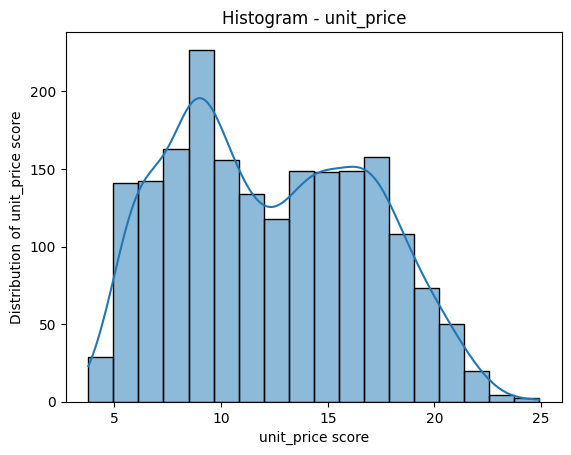

In [12]:
sns.histplot(export['unit_price'],kde = True)
plt.xlabel('unit_price score')
plt.ylabel('Distribution of unit_price score')
plt.title('Histogram - unit_price')
plt.show()

In [13]:
export['unit_price'].median()

11.93

In [14]:
export['unit_price']=export['unit_price'].fillna(export['unit_price'].median())

In [15]:
export.isna().sum()

,0
country,0
product_category,0
quantity,0
unit_price,0
discount_pct,0
total_amount,0
shipping_mode,0
shipping_days,39
payment_terms,29
delayed,0


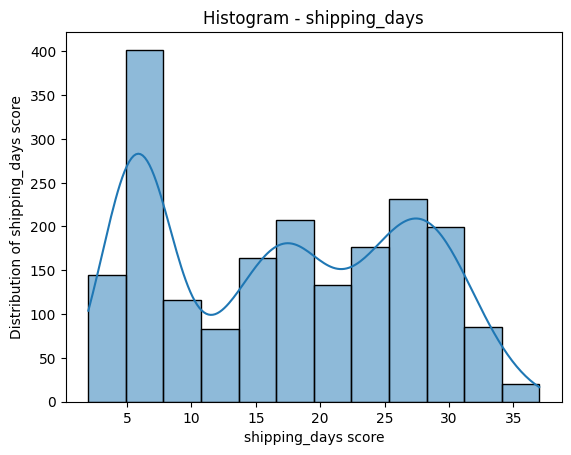

In [16]:
sns.histplot(export['shipping_days'],kde=True)
plt.xlabel('shipping_days score')
plt.ylabel('Distribution of shipping_days score')
plt.title('Histogram - shipping_days')
plt.show()

In [17]:
export['shipping_days'].median()

18.0

In [18]:
export['shipping_days']=export['shipping_days'].fillna(export['shipping_days'].median())

In [19]:
export.isna().sum()

,0
country,0
product_category,0
quantity,0
unit_price,0
discount_pct,0
total_amount,0
shipping_mode,0
shipping_days,0
payment_terms,29
delayed,0


In [20]:
export['payment_terms'].unique()

array(['LC', 'Net30', 'Advance', 'Net60', nan], dtype=object)

In [21]:
export['payment_terms'].value_counts()

,count
payment_terms,
LC,609
Net30,605
Advance,491
Net60,266


In [22]:
export['payment_terms'].mode()[0]

'LC'

In [24]:
export['payment_terms']=export['payment_terms'].fillna(export['payment_terms'].mode()[0])

In [25]:
export.isna().sum()

,0
country,0
product_category,0
quantity,0
unit_price,0
discount_pct,0
total_amount,0
shipping_mode,0
shipping_days,0
payment_terms,0
delayed,0


# handling outliers


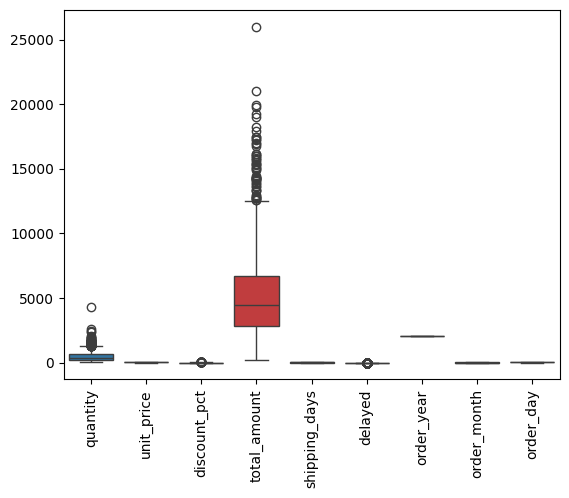

In [26]:
sns.boxplot(export)
plt.xticks(rotation=90)
plt.show()

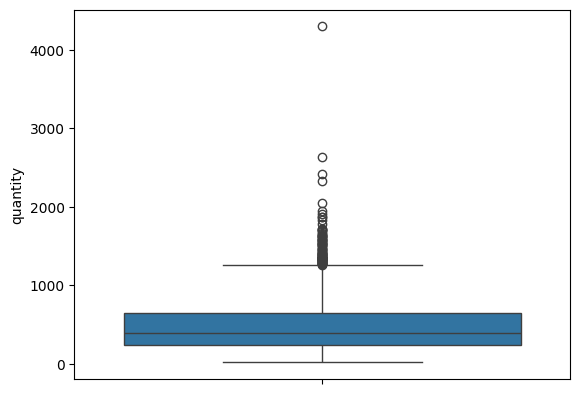

In [27]:
sns.boxplot(export['quantity'])
plt.show()

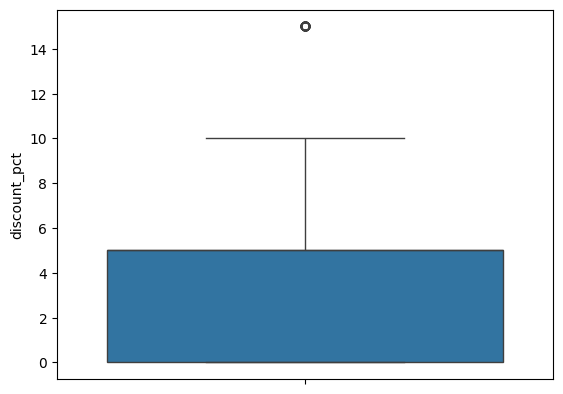

In [28]:
sns.boxplot(export['discount_pct'])
plt.show()

In [30]:
#outlier count
numeric_cols = export.select_dtypes(include=['int64', 'float64']).columns

# Remove target column
numeric_cols = numeric_cols.drop('delayed')

for col in numeric_cols:
    Q1 = export[col].quantile(0.25)
    Q3 = export[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = ((export[col] < lower_limit) | (export[col] > upper_limit)).sum()

    print(f"{col}: {outlier_count} outliers")

quantity: 85 outliers
unit_price: 0 outliers
discount_pct: 53 outliers
total_amount: 54 outliers
shipping_days: 0 outliers


In [31]:
export_1 = export.copy()

# Encoding

In [32]:
export.select_dtypes(include='object').columns

Index(['country', 'product_category', 'shipping_mode', 'payment_terms'], dtype='object')

In [33]:
categorical_cols = ['country', 'product_category', 'shipping_mode', 'payment_terms']

In [34]:
export = pd.get_dummies(export, columns=categorical_cols, drop_first=True,dtype=int)
export.head()

,quantity,unit_price,discount_pct,total_amount,shipping_days,delayed,order_year,order_month,order_day,country_Germany,...,product_category_Coir Products,product_category_Rubber Goods,product_category_Seafood,product_category_Spices,product_category_Tea,product_category_Textiles,shipping_mode_Sea,payment_terms_LC,payment_terms_Net30,payment_terms_Net60
0,301,17.97,5,5138.52,12.0,0,2025,1,1,0,...,0,0,0,1,0,0,1,1,0,0
1,637,5.80,5,3509.87,17.0,0,2025,1,2,0,...,1,0,0,0,0,0,1,0,1,0
2,896,12.20,0,10931.20,29.0,1,2025,1,2,0,...,0,0,0,0,0,1,1,0,0,0
3,435,8.52,5,3520.89,17.0,0,2025,1,2,0,...,0,0,0,0,1,0,1,0,0,0
4,304,7.57,0,2301.28,29.0,1,2025,1,3,0,...,0,0,0,0,1,0,1,1,0,0


In [35]:
x = export.drop('delayed', axis=1)
y = export['delayed']

KMEANS

In [36]:
# using elbow method to find the optimum number of clusters
from sklearn.cluster import KMeans

wcss = []
for i in  range(3,9):
  kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42,n_init=10)
  kmeans.fit(x)
  wcss.append (kmeans.inertia_)

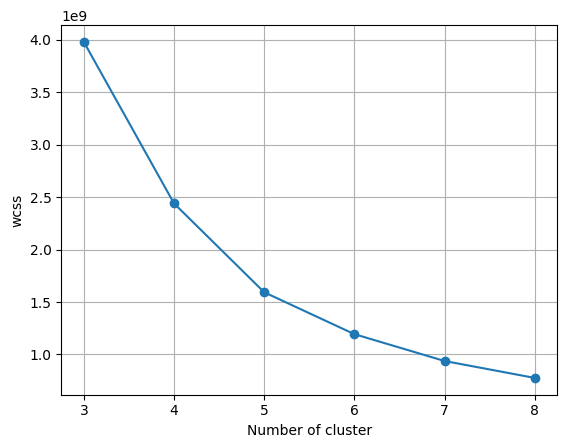

In [37]:
plt.plot(range(3,9),wcss,'o-')
plt.xlabel('Number of cluster')
plt.ylabel('wcss')
plt.grid()

In [38]:
#elbow is appearing at k= 5
# we can create kmeans model with no of  clusters = 5

kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(x)

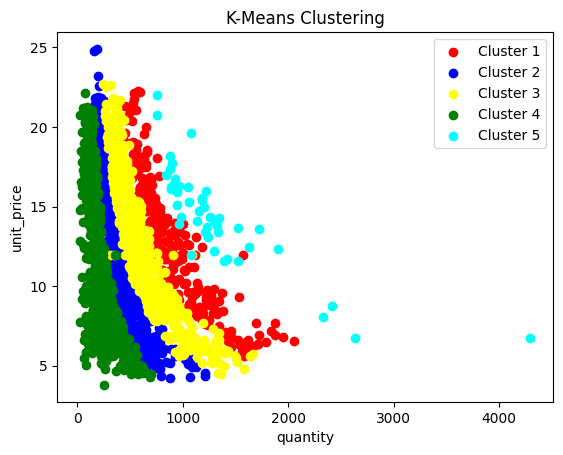

In [39]:
# Access the underlying numpy array of the DataFrame x using .values to allow 2D slicing
x_arr = x.values

plt.scatter(x_arr[y_kmeans == 0, 0], x_arr[y_kmeans == 0, 1], c='red', label='Cluster 1')
plt.scatter(x_arr[y_kmeans == 1, 0], x_arr[y_kmeans == 1, 1], c='blue', label='Cluster 2')
plt.scatter(x_arr[y_kmeans == 2, 0], x_arr[y_kmeans == 2, 1], c='yellow', label='Cluster 3')
plt.scatter(x_arr[y_kmeans == 3, 0], x_arr[y_kmeans == 3, 1], c='green', label='Cluster 4')
plt.scatter(x_arr[y_kmeans == 4, 0], x_arr[y_kmeans == 4, 1], c='cyan', label='Cluster 5')

# Label with actual column names for clarity
plt.xlabel(x.columns[0])
plt.ylabel(x.columns[1])
plt.title('K-Means Clustering')
plt.legend()
plt.show()

In [40]:
# stilhoutte score for kmeans clustering
from sklearn.metrics import silhouette_score
sil_kmeans = silhouette_score(x,y_kmeans)

In [41]:
sil_kmeans

np.float64(0.5228184925654378)

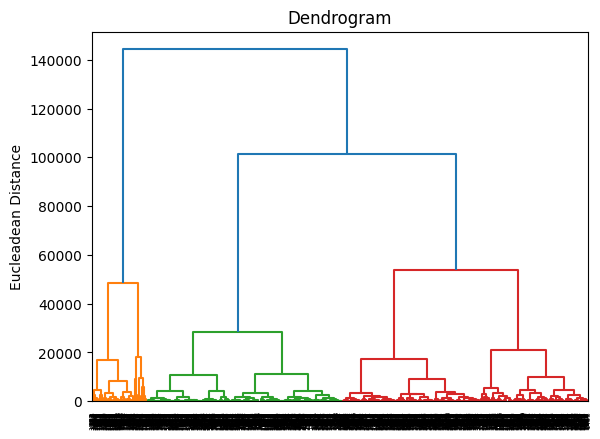

In [42]:
# using dendrogram to find the optimum number of clusters
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

# Avoid overwriting sch.dendrogram with the output dictionary
dendrogram_data = sch.dendrogram(sch.linkage(x, method = 'ward'))
plt.title("Dendrogram")
plt.xlabel("")
plt.xticks(rotation=90)
plt.ylabel("Eucleadean Distance")
plt.show()

In [43]:
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters = 3 , linkage= 'ward')
y_hc = hc.fit_predict(x)

In [44]:
silhouette_avg = silhouette_score(x,y_hc)
print(silhouette_avg)

0.5183007237316721


In [45]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
x_scaled = scaler.fit_transform(x)
x = pd.DataFrame(x_scaled, columns=x.columns)
x.head()

,quantity,unit_price,discount_pct,total_amount,shipping_days,order_year,order_month,order_day,country_Germany,country_Netherlands,...,product_category_Coir Products,product_category_Rubber Goods,product_category_Seafood,product_category_Spices,product_category_Tea,product_category_Textiles,shipping_mode_Sea,payment_terms_LC,payment_terms_Net30,payment_terms_Net60
0,0.065670,0.671557,0.333333,0.192393,0.285714,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
1,0.144193,0.095599,0.333333,0.129345,0.428571,0.0,0.0,0.033333,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,0.204721,0.398486,0.000000,0.416641,0.771429,0.0,0.0,0.033333,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,0.096985,0.224326,0.333333,0.129771,0.428571,0.0,0.0,0.033333,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0.066371,0.179366,0.000000,0.082558,0.771429,0.0,0.0,0.066667,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0


In [46]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=1.1, min_samples=3)

y_dbscan = dbscan.fit_predict(x)

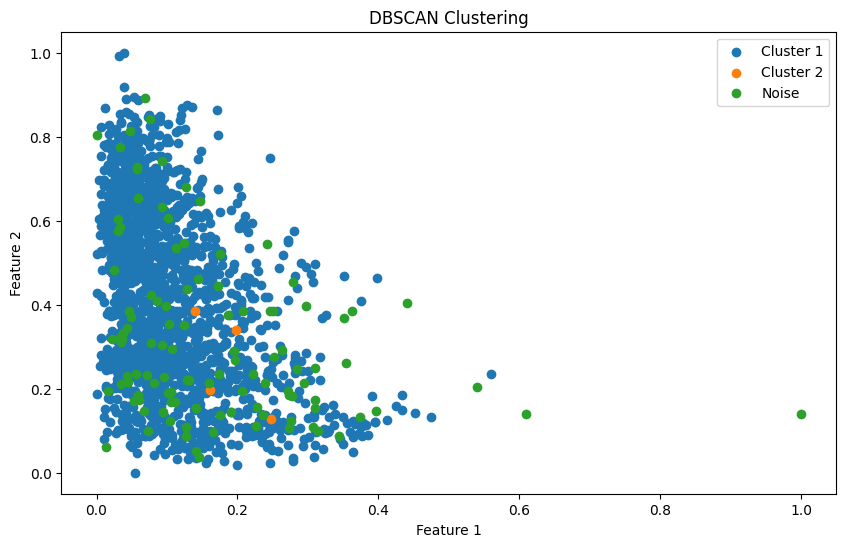

In [47]:
plt.figure(figsize=(10, 6))
x_dense = x.values

plt.scatter(x_dense[y_dbscan == 0, 0], x_dense[y_dbscan == 0, 1], label='Cluster 1')
plt.scatter(x_dense[y_dbscan == 1, 0], x_dense[y_dbscan == 1, 1], label='Cluster 2')
plt.scatter(x_dense[y_dbscan == -1, 0], x_dense[y_dbscan == -1, 1], label='Noise')

# Corrected the typo plt.x_denselabel -> plt.xlabel
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('DBSCAN Clustering')
plt.legend()
plt.show()

#Feature Reduction

<Axes: >

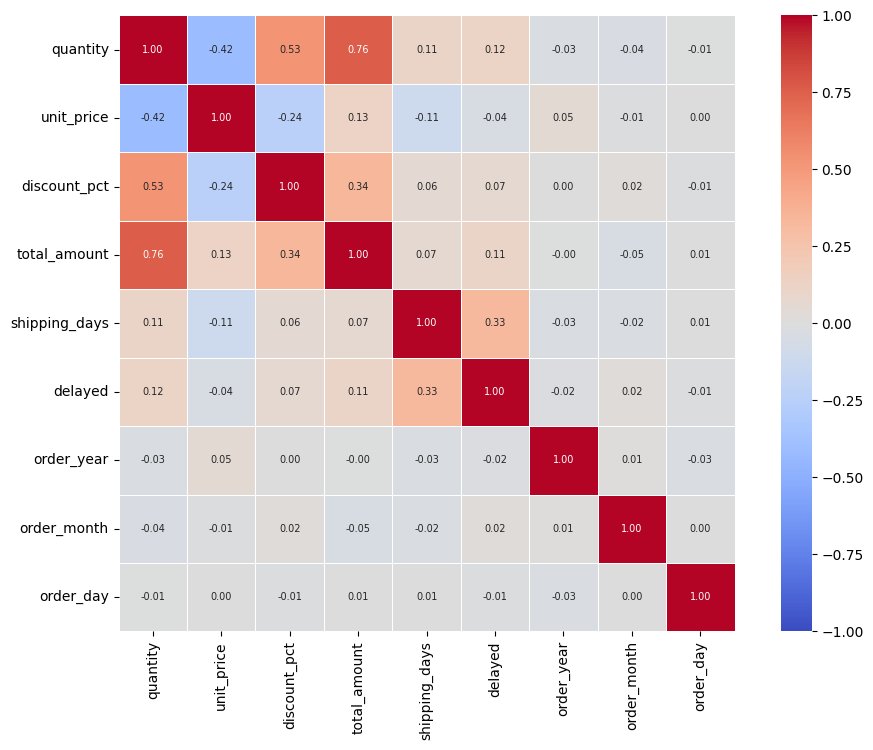

In [48]:
corr = export_1.corr(numeric_only=True)

plt.figure(figsize=(12,8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={"size":7}
)

In [49]:
export_1.columns

Index(['country', 'product_category', 'quantity', 'unit_price', 'discount_pct',
       'total_amount', 'shipping_mode', 'shipping_days', 'payment_terms',
       'delayed', 'order_year', 'order_month', 'order_day'],
      dtype='object')

In [50]:
export_1.drop(['payment_terms','order_year', 'order_month', 'order_day'],axis=1 ,inplace=True)

In [51]:
export_1.columns

Index(['country', 'product_category', 'quantity', 'unit_price', 'discount_pct',
       'total_amount', 'shipping_mode', 'shipping_days', 'delayed'],
      dtype='object')

In [52]:
categorical_cols = ['country', 'product_category', 'shipping_mode']

In [53]:
export_1 = pd.get_dummies(export_1, columns=categorical_cols, drop_first=True,dtype=int)
export_1.head()

,quantity,unit_price,discount_pct,total_amount,shipping_days,delayed,country_Germany,country_Netherlands,country_Saudi Arabia,country_Singapore,country_UAE,country_UK,country_USA,product_category_Coir Products,product_category_Rubber Goods,product_category_Seafood,product_category_Spices,product_category_Tea,product_category_Textiles,shipping_mode_Sea
0,301,17.97,5,5138.52,12.0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1
1,637,5.80,5,3509.87,17.0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1
2,896,12.20,0,10931.20,29.0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1
3,435,8.52,5,3520.89,17.0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1
4,304,7.57,0,2301.28,29.0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,1


In [55]:
x = export_1.drop('delayed', axis=1)
y = export_1['delayed']

KMEANS

In [56]:
# using elbow method to find the optimum number of clusters
from sklearn.cluster import KMeans

wcss = []
for i in  range(3,9):
  kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42,n_init=10)
  kmeans.fit(x)
  wcss.append (kmeans.inertia_)

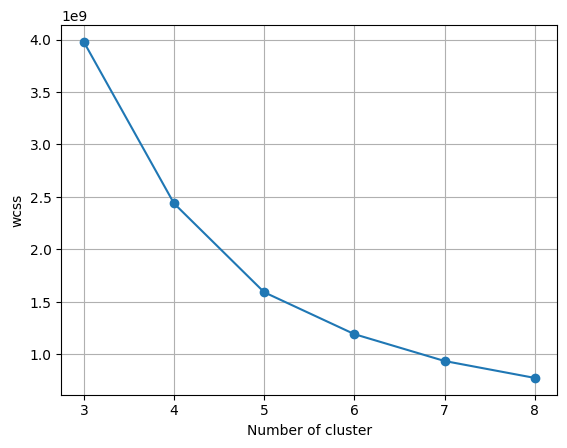

In [57]:
plt.plot(range(3,9),wcss,'o-')
plt.xlabel('Number of cluster')
plt.ylabel('wcss')
plt.grid()

In [58]:
#elbow is appearing at k= 5
# we can create kmeans model with no of  clusters = 5

kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(x)

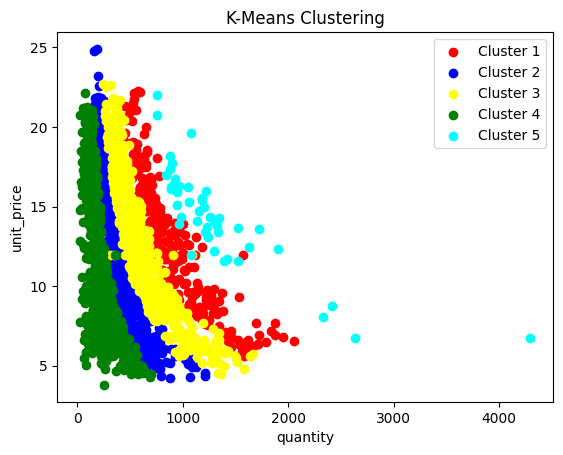

In [59]:
# Access the underlying numpy array of the DataFrame x using .values to allow 2D slicing
x_arr = x.values

plt.scatter(x_arr[y_kmeans == 0, 0], x_arr[y_kmeans == 0, 1], c='red', label='Cluster 1')
plt.scatter(x_arr[y_kmeans == 1, 0], x_arr[y_kmeans == 1, 1], c='blue', label='Cluster 2')
plt.scatter(x_arr[y_kmeans == 2, 0], x_arr[y_kmeans == 2, 1], c='yellow', label='Cluster 3')
plt.scatter(x_arr[y_kmeans == 3, 0], x_arr[y_kmeans == 3, 1], c='green', label='Cluster 4')
plt.scatter(x_arr[y_kmeans == 4, 0], x_arr[y_kmeans == 4, 1], c='cyan', label='Cluster 5')

# Label with actual column names for clarity
plt.xlabel(x.columns[0])
plt.ylabel(x.columns[1])
plt.title('K-Means Clustering')
plt.legend()
plt.show()

In [60]:
# stilhoutte score for kmeans clustering
from sklearn.metrics import silhouette_score
sil_kmeans = silhouette_score(x,y_kmeans)

In [61]:
sil_kmeans

np.float64(0.5229001887045658)

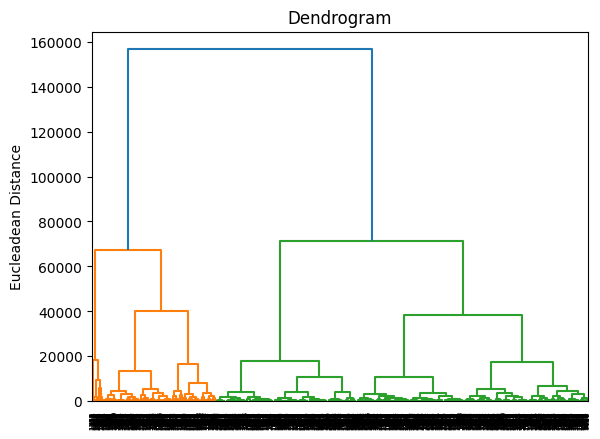

In [62]:
# using dendrogram to find the optimum number of clusters
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

# Avoid overwriting sch.dendrogram with the output dictionary
dendrogram_data = sch.dendrogram(sch.linkage(x, method = 'ward'))
plt.title("Dendrogram")
plt.xlabel("")
plt.xticks(rotation=90)
plt.ylabel("Eucleadean Distance")
plt.show()

In [63]:
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters = 2 , linkage= 'ward')
y_hc = hc.fit_predict(x)

In [64]:
silhouette_avg = silhouette_score(x,y_hc)
print(silhouette_avg)

0.5975560255843815


In [65]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
x_scaled = scaler.fit_transform(x)
x = pd.DataFrame(x_scaled, columns=x.columns)
x.head()

,quantity,unit_price,discount_pct,total_amount,shipping_days,country_Germany,country_Netherlands,country_Saudi Arabia,country_Singapore,country_UAE,country_UK,country_USA,product_category_Coir Products,product_category_Rubber Goods,product_category_Seafood,product_category_Spices,product_category_Tea,product_category_Textiles,shipping_mode_Sea
0,0.065670,0.671557,0.333333,0.192393,0.285714,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,0.144193,0.095599,0.333333,0.129345,0.428571,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.204721,0.398486,0.000000,0.416641,0.771429,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
3,0.096985,0.224326,0.333333,0.129771,0.428571,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,0.066371,0.179366,0.000000,0.082558,0.771429,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0


In [66]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=1.1, min_samples=3)

y_dbscan = dbscan.fit_predict(x)

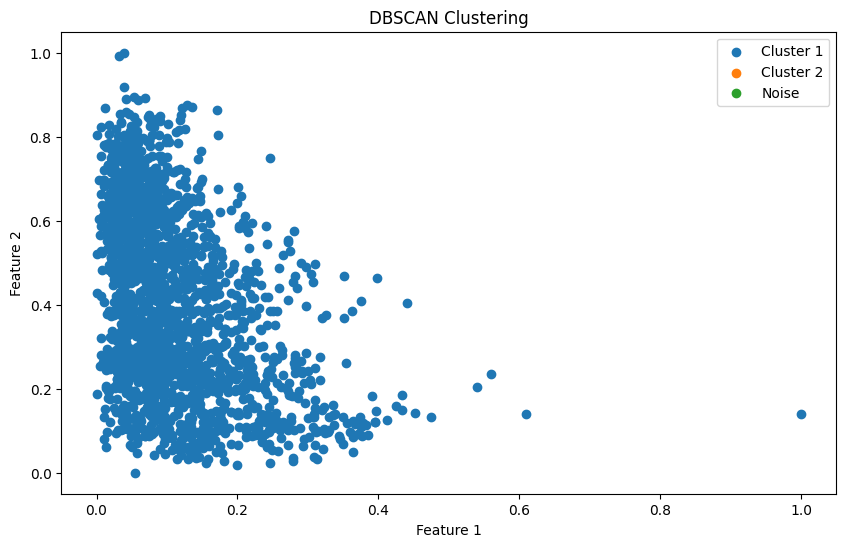

In [67]:
plt.figure(figsize=(10, 6))
x_dense = x.values

plt.scatter(x_dense[y_dbscan == 0, 0], x_dense[y_dbscan == 0, 1], label='Cluster 1')
plt.scatter(x_dense[y_dbscan == 1, 0], x_dense[y_dbscan == 1, 1], label='Cluster 2')
plt.scatter(x_dense[y_dbscan == -1, 0], x_dense[y_dbscan == -1, 1], label='Noise')

# Corrected the typo plt.x_denselabel -> plt.xlabel
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('DBSCAN Clustering')
plt.legend()
plt.show()

#dimension reduction

In [68]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA().fit(x)

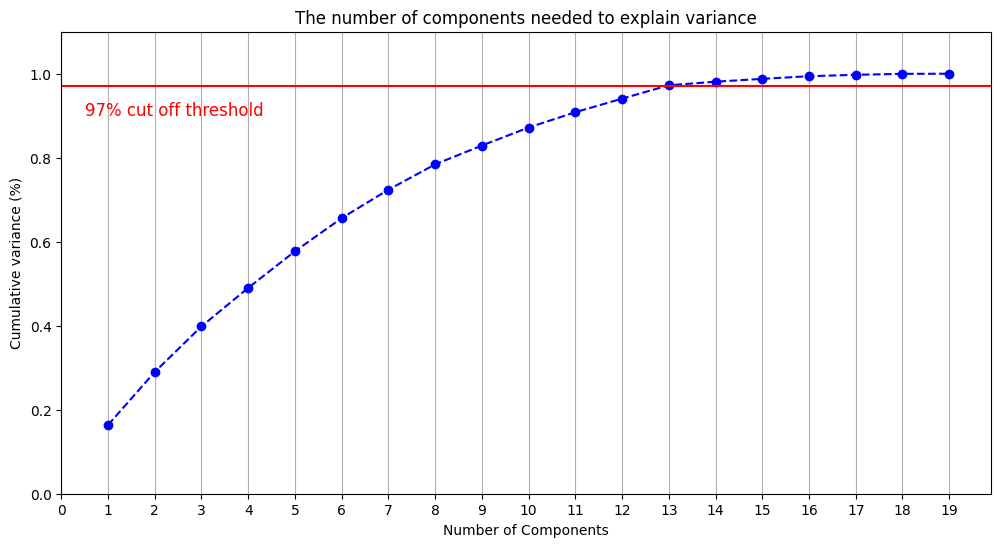

In [69]:
plt.rcParams["figure.figsize"] = (12, 6)
fig, ax = plt.subplots()
num_features = pca.n_components_
xi = np.arange(1, num_features + 1, step=1)
yi = np.cumsum(pca.explained_variance_ratio_)
plt.ylim(0.0, 1.1)
plt.plot(xi, yi, marker='o', linestyle='--', color='b')
plt.xlabel('Number of Components')
plt.xticks(np.arange(0, num_features + 1, step=1))
plt.ylabel('Cumulative variance (%)')
plt.title('The number of components needed to explain variance')
plt.axhline(y=0.97, color = "r", linestyle= '-')
plt.text(0.5, 0.9, "97% cut off threshold", color='red', fontsize =12)
ax.grid(axis='x')
plt.show()

In [70]:
#perform PCA
pca = PCA(n_components=13)   #Reduce dimensions to 9 for demostration
pca.fit(x)

#Transform the dataset
X_pca = pca.transform(x)

pca.get_covariance()  #Covariance matrix
explained_variance=pca.explained_variance_ratio_
explained_variance

array([0.16363447, 0.12625618, 0.10852241, 0.09168736, 0.08707165,
       0.07900747, 0.06770006, 0.06029104, 0.04484854, 0.04290377,
       0.03643516, 0.0323101 , 0.03184549])

In [71]:
#convert tranformed data into Dataframe
df_pca = pd.DataFrame(X_pca,
                      columns=['PC1','PC2','PC3','PC4','PC5','PC6','PC7','PC8','PC9','PC10','PC11','PC12','PC13'])
df_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
0,0.122171,0.834069,0.872356,-0.026308,0.177178,-0.094730,0.096734,-0.038158,-0.057839,-0.091058,0.084496,0.155979,-0.099809
1,0.308591,-0.355278,-0.019478,-0.277939,0.278092,0.836909,-0.578500,0.671384,-0.257322,0.167420,-0.157777,-0.046790,-0.058019
2,0.597273,-0.115362,-0.581215,-0.639223,0.004502,-0.792837,0.236369,0.119201,-0.082293,0.068192,-0.198696,-0.178420,-0.009892
3,0.184689,-0.492916,0.949946,0.502815,0.019625,-0.389141,0.053392,0.071145,-0.071232,0.034904,-0.004908,0.109920,-0.008878
4,0.462838,-0.477955,-0.050733,0.886888,-0.455204,0.188667,0.597700,0.010476,-0.122323,0.227770,-0.193810,-0.113731,0.049359
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,0.102108,-0.501529,0.969013,0.492972,0.015400,-0.380946,0.050973,0.093854,-0.080326,-0.016803,0.009003,0.111460,-0.028385
1996,0.080623,-0.070683,0.839517,-0.200707,0.088128,-0.114854,0.082915,-0.010261,0.089231,0.209055,0.094449,0.003360,-0.060839
1997,-0.747333,-0.513253,0.769755,0.521535,0.087701,-0.403083,0.084032,0.031260,-0.249538,-0.291690,0.026177,-0.023441,0.070844
1998,0.471304,-0.116651,-0.289104,-0.423870,-0.913475,0.093006,0.706713,0.050827,-0.134272,0.020017,-0.076889,0.064848,-0.093917


### K-Means Clustering on PCA-Reduced Data

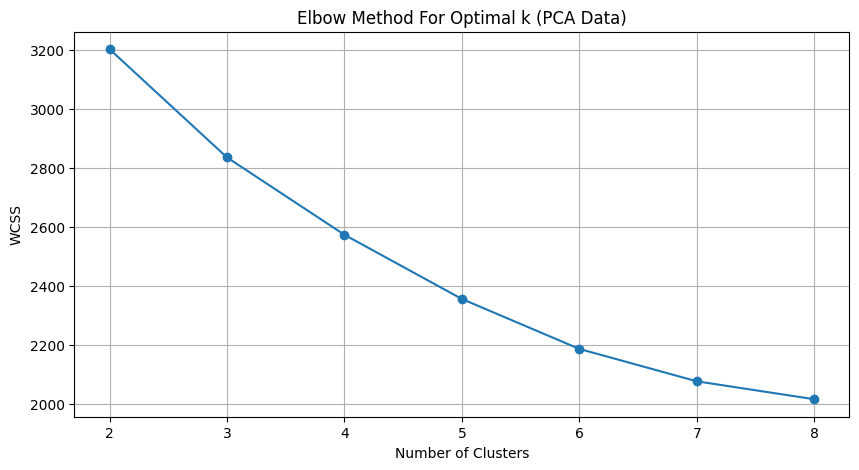

In [72]:
# Use elbow method to find the optimum number of clusters on the PCA components
wcss_pca = []
for i in range(2, 9):
    kmeans_pca = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans_pca.fit(df_pca)
    wcss_pca.append(kmeans_pca.inertia_)

# Plot the elbow curve
plt.figure(figsize=(10, 5))
plt.plot(range(2, 9), wcss_pca, 'o-')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method For Optimal k (PCA Data)')
plt.grid(True)
plt.show()

In [73]:
# Based on the elbow plot, let's fit K-Means (using k=5 for comparison, or adjust based on the plot)
k_optimal = 6
kmeans_pca = KMeans(n_clusters=k_optimal, init='k-means++', random_state=42, n_init=10)
y_kmeans_pca = kmeans_pca.fit_predict(df_pca)

# Calculate silhouette score for K-Means on PCA data
sil_kmeans_pca = silhouette_score(df_pca, y_kmeans_pca)
print(f"Silhouette Score for K-Means with {k_optimal} clusters on PCA components: {sil_kmeans_pca:.4f}")

Silhouette Score for K-Means with 6 clusters on PCA components: 0.2072


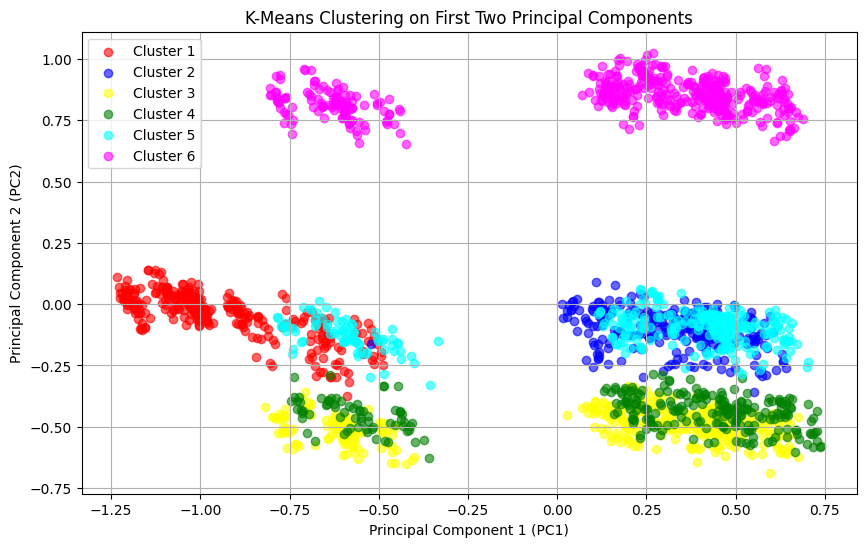

In [76]:
# Visualize the clusters using the first two Principal Components (PC1 and PC2)
plt.figure(figsize=(10, 6))
colors = ['red', 'blue', 'yellow', 'green', 'cyan', 'magenta']

for i in range(k_optimal):
    plt.scatter(
        df_pca.loc[y_kmeans_pca == i, 'PC1'],
        df_pca.loc[y_kmeans_pca == i, 'PC2'],
        c=colors[i],
        label=f'Cluster {i+1}',
        alpha=0.6
    )

plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('K-Means Clustering on First Two Principal Components')
plt.legend()
plt.grid(True)
plt.show()